Tarea Selección de Variables
===========
Isac Añor Santana
---

Ciencia de Datos en Ingeniería – Curso 2026/27
Máster SIANI

# Introduccion

## Seleccion de variables
En el análisis de datos modernos, los conjuntos de datos suelen contener cientos o miles de variables. Muchas características son redundantes, irrelevantes o simplemente ruido que confunde a los modelos de aprendizaje automático. La selección de variables busca identificar y conservar únicamente las características realmente útiles, eliminando el resto. Esto mejora la capacidad predictiva del modelo, reduce costes computacionales, facilita la interpretación de los resultados y, en aplicaciones reales como diagnósticos médicos, puede significar ahorrar pruebas clínicas innecesarias.

Uno de los principales riesgos de trabajar con demasiadas variables es el sobreajuste: el modelo memoriza patrones específicos de los datos de entrenamiento en lugar de aprender relaciones generales, perdiendo capacidad para predecir correctamente con nuevos datos. Además, ciertos algoritmos son sensibles a valores extremos (outliers) que pueden distorsionar completamente la estructura del conjunto. Por ejemplo, métodos basados en distancias o varianzas como el PCA pueden verse gravemente afectados por unos pocos puntos atípicos que "tirarán" de las componentes principales hacia direcciones espurias. La selección previa de variables ayuda a mitigar estos problemas al reducir la dimensionalidad antes de aplicar cualquier modelado complejo.

Dado que el número total de combinaciones posibles de variables crece exponencialmente —con 30 atributos existen más de mil millones de subconjuntos— resulta imposible evaluarlos todos exhaustivamente en un tiempo razonable. Aquí entran las heurísticas: estrategias de búsqueda inteligente que encuentran buenas soluciones sin garantizar el óptimo absoluto, pero sí con un coste computacional manejable. Métodos como la búsqueda secuencial hacia adelante (SFS) o hacia atrás (SBS) construyen el subconjunto añadiendo o eliminando una variable a la vez, aunque tienen la limitación de no poder corregir decisiones tomadas previamente.

El algoritmo que se implementa en esta práctica, la Búsqueda Bidireccional (BDS), combina lo mejor de ambos enfoques. Ejecuta simultáneamente una búsqueda que crece desde cero y otra que decrece desde el conjunto completo, manteniendo un registro compartido de decisiones irreversibles. Cada vez que una variable es seleccionada por el primer enfoque queda protegida para la segunda, y viceversa. Esta sincronización permite compensar los errores tempranos de cada estrategia por separado, convergiendo hacia un subconjunto final robusto.

## Declaracion de uso de Inteligencia Artifical
Se ha usado Inteligencia Artificial para el desarrollo de esta practica. El uso ha estado limitado a las siguientes tareas:
- Corrección ortografica (uso teclado con distribución norteamericana y no puedo cambiar el tipo de entrada en collab, por lo tanto he usado la propia IA integrada para agregar acentos y caracteres especiales. Es posible que falten en algun bloque de texto).
- Validación de bloques de texto.
- Revisión del código.
- Revisión de resultados y conclusiones.
- Asistencia y explicación de funciones y funcionalidad de las librerias empleadas.

El diseño del código desde un punto de vista de alto nivel: seleccion de abstracciones, colocación en los distintos bloques de código y otros detalles tecnicos (como la preferencia por programación funcional en la medida de lo posible) se ha hecho **SIN** inteligencia artificial. Bajo el criterio del alumno, estas decisiones no competen a la inteligencia artificial. Se ha preferido limitar el uso a tareas que **provean la informacion necesaria para tomar estas decisiones**.

# Descripción de los datos utilizados

## Descarga del conjunto de datos

In [21]:
!pip install ucimlrepo

In [24]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

# fetch dataset
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)

# data (as pandas dataframes)
X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

## Visor del conjunto de datos
Ejecucion de la libreria presentada en la practica anterior para visualizar el conjunto de datos de forma interactiva.

In [13]:
!pip install fg-data-profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 18.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 31.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [fg-data-profiling]


In [18]:
from data_profiling import ProfileReport
dataset_for_profile = pd.concat([X, y], axis=1)
report = dataset_for_profile.profile_report(sort='Ascending', html={'style':{'full_width':True}})
report

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 31/31 [00:00<00:00, 51.49it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [19]:
dataset_for_profile

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,M
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,M
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,M
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,M
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,M


## Estructura y Características del Dataset

El conjunto de datos "Breast Cancer Wisconsin (Diagnostic)" contiene características computadas a partir de imágenes digitalizadas de aspiraciones con aguja fina de masas mamarias. Cada variable describe propiedades de los núcleos celulares presentes en la imagen, las cuales han demostrado ser relevantes para diferenciar entre tumores benignos y malignos.

### Dimensiones y Calidad de Datos
- **Instancias**: 569 muestras en total.
- **Variables predictoras**: 30 atributos numéricos continuos.
- **Valores faltantes**: Ninguno; el dataset está completo sin nulos.

### Variables Predictoras (X)
Las 30 características se derivan de 10 medidas básicas calculadas en tres configuraciones estadísticas distintas: **Media**, **Error Estándar** y **Valor Peor** (el mayor valor entre las mediciones). Esto resulta en 10 × 3 = 30 variables en total. Las 10 medidas básicas son:

| Variable | Descripción |
|----------|-------------|
| `radius` | Media de distancias desde el centro del núcleo a sus puntos del perímetro |
| `texture` | Desviación estándar de los valores de escala de grises de la imagen |
| `perimeter` | Longitud del contorno del núcleo |
| `area` | Área del núcleo celular |
| `smoothness` | Variación local en las longitudes de radio |
| `compactness` | Compacidad: `(perímetro² / área) − 1.0` |
| `concavity` | Severidad de las porciones cóncavas del contorno |
| `concave_points` | Número de porciones cóncavas en el borde del núcleo |
| `symmetry` | Grado de simetría del núcleo |
| `fractal_dimension` | Medida de complejidad ("longitud de costa" − 1) |

Cada una de estas diez métricas se reporta como media, error estándar y valor peor, generando el conjunto final de 30 columnas.

### Variable Objetivo (y)
- **Nombre**: `Diagnosis`
- **Tipo**: Binaria categórica
- **Clases**:
  - **B** (Benigno): 357 instancias (~62.7%)
  - **M** (Maligno): 212 instancias (~37.3%)
- **Balance**: Ligera prevalencia de casos benignos, pero sin desequilibrio extremo.

Este dataset es ampliamente utilizado en la comunidad de aprendizaje automático debido a su tamaño manejable, calidad verificada y relevancia clínica directa. La tarea de clasificación tiene consecuencias reales en diagnósticos médicos, lo que subraya la importancia de modelos interpretables y precisos.

# Código de las funciones implementadas

## Implementación de las medidas
A continuacion se definen cuatro funciones para realizar el calculo de las medidas que usara el algoritmo de busqueda para determinar la calidad del subconjunto de caracteristicas seleccionado.

Dado que posteriormente se haran pruebas para cada una de las funciones, es importante que todas tengan la misma interfaz para poder llamarlas de manera indistinta. Las funciones recibiran como parametros:
1. Un dataframe de pandas con el subconjunto de caracteristicas seleccionado
2. El vector con las etiquetas de la clase (si el tumor es maligno o no)

### Varianza de la variable
La varianza mide cuánto se dispersan los valores de una característica alrededor de su media. En términos sencillos:

- Alta varianza → La variable toma muchos valores diferentes, cubre un amplio rango, "muestra diversidad" en los datos.
- Baja varianza → La variable tiene valores muy parecidos, casi constante, "no cambia mucho" entre muestras.

Cuando aplicamos esta medida a selección de variables, asumimos que una variable que casi no varía aporta poca información discriminativa. Teniendo como ejemplo este dataset, en el caso que la variable `radius` tenga el mismo valor para todas las observaciones, esta caracteristica seria inservible para determinar si el tumor es maligno o benigno pues ambos tienen el mismo valor.

### Correlacion de la variable con la clase
Se calcula usando la correlación de Pearson mide la intensidad y dirección de la relación lineal entre dos variables. En este contexto:

- Variable 1: Una característica del dataset (por ejemplo, radius_mean)
- Variable 2: La variable objetivo codificada como numérica (Benigno=0, Maligno=1)

El coeficiente de Pearson (r) varía entre -1 y 1:
|Valor|	Interpretación|
| --- | --- |
|r ≈ 1 |	Relación lineal positiva fuerte → Si aumenta la variable, aumenta la probabilidad de clase Maligna |
|r ≈ -1 |	Relación lineal negativa fuerte → Si aumenta la variable, disminuye la probabilidad de clase Maligna |
|r ≈ 0 |No hay relación lineal → La variable no discrimina entre clases |

Interesa la correlación absoluta, porque una relación negativa también es informativa. Lo importante es que exista asociación, no su dirección.

### Funcion de merito Correlation Feature Selection (CFS)
CFS evalúa la calidad considerando dos factores simultáneamente:

- Relevancia: ¿Qué tan correlacionadas están las variables con la clase?
- Redundancia: ¿Qué tan correlacionadas están entre sí las variables?

Un buen subconjunto debe tener variables que predigan bien la clase, pero que no digan básicamente lo mismo entre ellas. Como el ejemplo en clase de la graduacion de alcohol de la cerveza y la densidad.

Se define:

$$Merit(S) = \frac{k \bar{r}_{ic}}{\sqrt{k + k(k-1)\bar{r}_{ii}}}$$

Donde $\bar{r}_{ic}$ es la correlación promedio entre las variables del subconjunto y la clase, y $\bar{r}_{ii}$ es la correlación promedio inter-variable de las variables en $S$. Por lo tanto, cuanto mayor sea el numerador, mas alta sera la correlacion promedio con la clase, esto indica que el subconjunto es **relevante**. La redundancia esta en el denominador, cuanto mas correlacionadas esten las variables entre si, mayor sera el denominador, penalizando asi a los subconjuntos redundantes.

### Clasificador entrenado
Esta métrica entrena y evalúa un clasificador real usando las variables del subconjunto, y devuelve su precisión (accuracy) media.

A diferencia de las tres métricas anteriores que analizan propiedades estadísticas de los datos, esta mide directamente la utilidad práctica del subconjunto para resolver la tarea de clasificación.

El algoritmo que se usara es el siguiente:
```
┌─────────────────────────────────────────────────────────────────┐
│ WRAPPER ACCURACY ALGORITHM                                      │
├─────────────────────────────────────────────────────────────────┤
│ 1. Dividir dataset en k pliegues estratificados                 │
│ 2. Para cada pliegue i:                                         │
│    a. Usar pliegue i como test                                  │
│    b. Usar el resto como train                                  │
│    c. Entrenar clasificador KNN                                 │
│    d. Evaluar en test                                           │
│    e. Guardar precisión                                         │
│ 3. Retornar promedio de las k precisiones                       │
└─────────────────────────────────────────────────────────────────┘
```

In [26]:
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

def metric_variance(X_subset, y_true):
    """Calculates the average variance of the features in the subset."""
    return np.mean(np.var(X_subset, axis=0))

def metric_correlation(X_subset, y_true):
    """Calculates the average absolute correlation of features with the class."""
    correlations = [abs(np.corrcoef(X_subset[col], y_true)[0, 1]) for col in X_subset.columns]
    return np.mean(correlations)

def metric_cfs(X_subset, y_true):
    """Calculates the CFS merit score for the feature subset."""
    k = X_subset.shape[1]

    rcf = np.mean([abs(np.corrcoef(X_subset[col], y_true)[0, 1]) for col in X_subset.columns])

    if k == 1:
        return rcf

    correlation_matrix = np.abs(np.corrcoef(X_subset.values, rowvar=False))
    rff = (np.sum(correlation_matrix) - k) / (k * (k - 1))

    return (k * rcf) / np.sqrt(k + k * (k - 1) * rff)

def metric_wrapper(X_subset, y_true):
    """Calculates the 5-fold cross-validation accuracy using KNN."""
    clf = KNeighborsClassifier(n_neighbors=5)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    return cross_val_score(clf, X_subset, y_true, cv=cv, scoring='accuracy').mean()

## Implementacion del algoritmo de busqueda
BDS es esencialmente dos políticas de decisión (añadir / eliminar) operando sobre un estado común, coordinadas por un orquestador.

El diseno de la implementacion consiste en la definicion del estado comun seguido de dos funciones locales de paso para hacer la busqueda hacia adelante y la busqueda hacia atras. Las funciones se definen locales a proposito para que tengan acceso al alcance lexico del estado comun. Finalmente, se define el bucle de control y convergencia que llama a las funciones de paso y muta el estado.

In [25]:
def select_BDS(X, y, n_features, metric_func, trace=None):
    """Selects n_features columns from X using Bidirectional Search (BDS).

    Runs Sequential Forward Search (SFS) and Sequential Backward Search (SBS)
    in parallel over a shared registry of irreversible decisions: a feature
    committed by SFS can never be removed by SBS, and vice versa.

    Args:
        X: DataFrame with the candidate features.
        y: Target array.
        n_features: Number of features to select.
        metric_func: Callable (X_subset, y_true) -> float. Higher is better.
        trace: Optional list. If given, one dict per decision is appended.

    Returns:
        Binary numpy array of length X.shape[1]; 1 marks a selected feature.
    """
    columns = list(X.columns)
    n = len(columns)

    # Edge cases resolved before the search starts
    if not 0 <= n_features <= n:
        raise ValueError(f"n_features must be in [0, {n}], got {n_features}")
    if n_features == 0:
        return np.zeros(n, dtype=int)
    if n_features == n:
        return np.ones(n, dtype=int)

    # Shared registry of irreversible decisions
    added = set()      # committed as selected by SFS
    removed = set()    # committed as discarded by SBS

    def undecided():
        """Features not yet committed in either direction."""
        return [c for c in columns if c not in added and c not in removed]

    # Memoised evaluation: identical subsets are never scored twice
    cache = {}

    def evaluate(feature_set):
        key = frozenset(feature_set)
        if key not in cache:
            cache[key] = metric_func(X[sorted(key)], y)
        return cache[key]

    def forward_step():
        """Best feature to add to F. Returns (feature, score)."""
        best_feature, best_score = None, -np.inf
        for feature in sorted(undecided()):
            score = evaluate(added | {feature})
            if score > best_score:
                best_feature, best_score = feature, score
        return best_feature, best_score

    def backward_step():
        """Best feature to drop from B. Returns (feature, score)."""
        current_B = set(columns) - removed
        best_feature, best_score = None, -np.inf
        for feature in sorted(undecided()):
            score = evaluate(current_B - {feature})
            if score > best_score:
                best_feature, best_score = feature, score
        return best_feature, best_score

    # Convergence loop: each pass commits exactly one feature
    while len(added) < n_features or len(removed) < n - n_features:

        if len(added) < n_features:
            feature, score = forward_step()
            added.add(feature)
            if trace is not None:
                trace.append({"step": len(trace), "phase": "forward",
                              "feature": feature, "score": score,
                              "size_F": len(added),
                              "size_B": len(columns) - len(removed),
                              "evaluations": len(cache)})

        if len(removed) < n - n_features:
            feature, score = backward_step()
            removed.add(feature)
            if trace is not None:
                trace.append({"step": len(trace), "phase": "backward",
                              "feature": feature, "score": score,
                              "size_F": len(added),
                              "size_B": len(columns) - len(removed),
                              "evaluations": len(cache)})

    # At convergence F and B coincide by construction
    assert len(added) == n_features
    assert set(columns) - removed == added

    return np.array([1 if c in added else 0 for c in columns])

# Ejecución de diferentes pruebas

En este apartado se realizan ejecuciones para la seleccion de subconjuntos de 1 a 15 caracteristicas para las cuatro metricas implementadas. La ejecucion para las metrica de varianza se debe hacer sin escalar. Al estandarizar todas las columnas quedan con varianza = 1.

Shape: (569, 30)
Benign: 357 | Malignant: 212
                    variance  correlation     cfs  wrapper
Number of Features                                        
1                     0.9087       0.8928  0.8928   0.9087
2                     0.9332       0.9297  0.9368   0.9473
3                     0.9315       0.9333  0.9438   0.9560
4                     0.9473       0.9385  0.9684   0.9631
5                     0.9420       0.9473  0.9649   0.9631
6                     0.9473       0.9526  0.9649   0.9701
7                     0.9385       0.9526  0.9649   0.9719
8                     0.9456       0.9508  0.9666   0.9719
9                     0.9438       0.9438  0.9649   0.9754
10                    0.9420       0.9420  0.9614   0.9737
11                    0.9420       0.9455  0.9649   0.9754
12                    0.9385       0.9420  0.9666   0.9701
13                    0.9631       0.9420  0.9701   0.9701
14                    0.9543       0.9385  0.9649   0.9666
15        

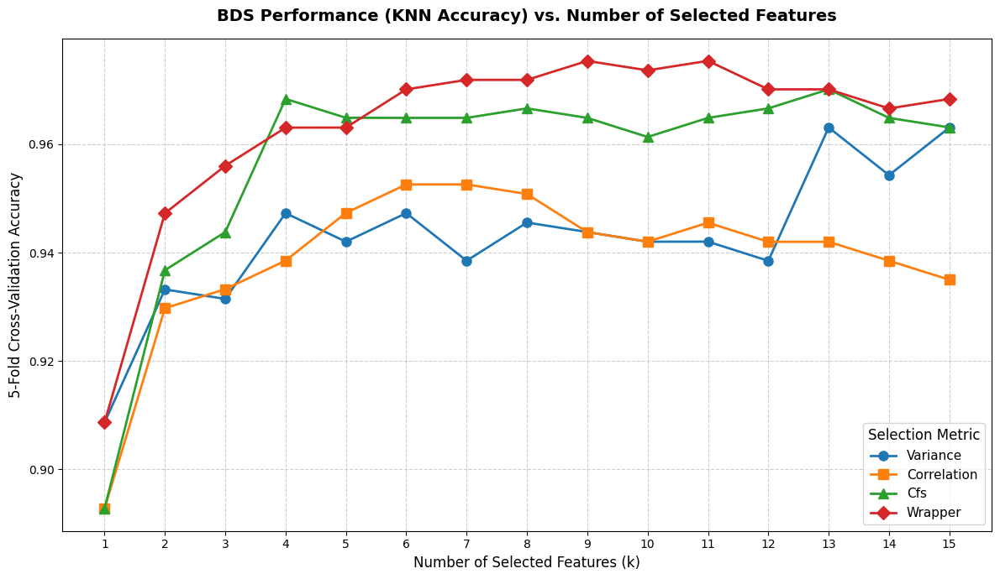

In [29]:
from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# 1. Load and prepare data
# ------------------------------------------------------------------
dataset = fetch_ucirepo(id=17)
X_raw = dataset.data.features
y_raw = dataset.data.targets

y_encoded = y_raw.iloc[:, 0].map({'M': 1, 'B': 0}).values

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_raw), columns=X_raw.columns)

print(f"Shape: {X_raw.shape}")
print(f"Benign: {(y_encoded == 0).sum()} | Malignant: {(y_encoded == 1).sum()}")

# ------------------------------------------------------------------
# 2. Experiment registry: (name, metric function, matrix for selection)
# ------------------------------------------------------------------
EXPERIMENTS = [
    ('variance',    metric_variance,    X_raw),     # only meaningful in original units
    ('correlation', metric_correlation, X_scaled),
    ('cfs',         metric_cfs,         X_scaled),
    ('wrapper',     metric_wrapper,     X_scaled),
]

# ------------------------------------------------------------------
# 3. Experimentation loop
# ------------------------------------------------------------------
K_RANGE = range(1, 16)
RESULTS = {name: [] for name, _, _ in EXPERIMENTS}

for k in K_RANGE:
    for name, metric_func, X_data in EXPERIMENTS:
        vector = select_BDS(X_data, y_encoded, k, metric_func)
        selected_columns = X_scaled.columns[vector == 1]
        RESULTS[name].append(metric_wrapper(X_scaled[selected_columns], y_encoded))

# ------------------------------------------------------------------
# 4. Results table
# ------------------------------------------------------------------
df_results = pd.DataFrame(RESULTS, index=list(K_RANGE))
df_results.index.name = 'Number of Features'
print(df_results.round(4).to_string())

# ------------------------------------------------------------------
# 5. Visualization
# ------------------------------------------------------------------
plt.figure(figsize=(12, 7))
styles = {
    'variance':    ('#1f77b4', 'o'),
    'correlation': ('#ff7f0e', 's'),
    'cfs':         ('#2ca02c', '^'),
    'wrapper':     ('#d62728', 'D'),
}

for name, _, _ in EXPERIMENTS:
    color, marker = styles[name]
    plt.plot(list(K_RANGE), RESULTS[name], label=name.capitalize(),
             color=color, marker=marker, linewidth=2, markersize=8)

plt.title('BDS Performance (KNN Accuracy) vs. Number of Selected Features',
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Selected Features (k)', fontsize=12)
plt.ylabel('5-Fold Cross-Validation Accuracy', fontsize=12)
plt.xticks(list(K_RANGE))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Selection Metric', fontsize=11, title_fontsize=12, loc='lower right')
plt.tight_layout()
plt.show()

# Análisis de resultados

De las cuatro formas de medir la calidad de un subconjunto, dos destacan claramente por encima de las demás: el mérito CFS y la tasa de acierto del clasificador (wrapper). CFS es la mejor opción porque es la única que tiene en cuenta dos cosas a la vez: si cada variable ayuda a distinguir entre tumor benigno y maligno, y si las variables se repiten entre sí. Gracias a eso alcanza un resultado alto (en torno a 0.97) ya con solo cuatro variables y se mantiene estable hasta el final, sin importar cuántas variables se elijan. El wrapper obtiene la cifra más alta de la tabla (0.9754), pero su ventaja sobre CFS es de apenas medio punto porcentual y su coste es enormemente mayor, porque para cada subconjunto que prueba tiene que entrenar y evaluar un clasificador cinco veces. Además, su resultado está ligeramente inflado, ya que selecciona las variables usando las mismas particiones de datos con las que luego se evalúa.

La correlación con la clase y la varianza se quedan por detrás, y cada una por un motivo distinto. La correlación mira cada variable por separado y no se da cuenta de que muchas están duplicadas (radio, perímetro y área miden prácticamente lo mismo). Por eso empieza muy bien, mejora hasta 0.9526 con seis o siete variables, y a partir de ahí empeora: seguir añadiendo variables parecidas no aporta información nueva y además perjudica al clasificador. La varianza es todavía más floja como criterio porque no mira el diagnóstico en absoluto: solo premia las variables cuyos valores están más dispersos. Empieza sorprendentemente bien (0.9087 con una sola variable) porque en este conjunto las variables de tamaño, que son las más dispersas, también resultan ser buenas predictoras. Pero ese acierto es casualidad, no una guía real, y por eso su curva sube y baja sin rumbo fijo en lugar de mejorar de forma ordenada.

En resumen, lo que marca la diferencia no es usar el método más caro, sino elegir un criterio que tenga en cuenta la redundancia entre variables. CFS logra prácticamente el mismo resultado que el wrapper con un coste muchísimo menor y sin depender del clasificador que se use después. Por eso la recomendación práctica es usar CFS y quedarse con unas 7 a 9 variables: se conserva casi toda la capacidad predictiva (alrededor del 97%) reduciendo el problema a menos de un tercio de su tamaño original.